# 02 — Analyse exploratoire (EDA)

**Rôle de ce notebook** : explorer la table maître produite par `01_data_preparation.ipynb`
(`Data/processed/train_master.csv`), au grain parcelle × mois de récolte (1629 lignes).

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_style("whitegrid")

DATA_DIR = Path(r"C:\Github_Projects\Competition_Kaggle\Kaggle_competition\Data")
train = pd.read_csv(DATA_DIR / "processed" / "train_master.csv")
train["Date"] = pd.to_datetime(train["Date"])
print(train.shape)
train.head(3)


(1629, 61)


,id,Campagne,Region,Code Ferme,Libelle Site,Libelle Variete,Num Parcelle,CodeTracabilite,Date,Tonnage (Kg),Date Plantation,Porte Greffe,Surface,parcelle_info_manquante,Age_recolte,year,month,age_incoherente,month_idx,Irrigation_m3_cum_1m,N_cum_1m,P_cum_1m,K_cum_1m,Irrigation_m3_cum_3m,N_cum_3m,P_cum_3m,K_cum_3m,Irrigation_m3_cum_6m,N_cum_6m,P_cum_6m,...,Irrigation_m3_cum_12m,N_cum_12m,P_cum_12m,K_cum_12m,log_tonnage,domaine_climat_effectif,TemperatureMax_C,TemperatureMin_C,TemperatureMoy_C,HumiditeRelativeMax_pct,HumiditeRelativeMin_pct,HumiditeRelativeMoy_pct,ET0_mm,climat_source,TemperatureMax_C_roll3m,TemperatureMin_C_roll3m,TemperatureMoy_C_roll3m,HumiditeRelativeMax_pct_roll3m,HumiditeRelativeMin_pct_roll3m,HumiditeRelativeMoy_pct_roll3m,ET0_mm_roll3m,TemperatureMax_C_roll6m,TemperatureMin_C_roll6m,TemperatureMoy_C_roll6m,HumiditeRelativeMax_pct_roll6m,HumiditeRelativeMin_pct_roll6m,HumiditeRelativeMoy_pct_roll6m,ET0_mm_roll6m,rendement_N-1,rendement_N-1_manquant
0,0,20/21,GHARB,Ferme 1,Site 1,Variete1,14010,TR14010,2020-11-01,325208.0,2005-06-01 00:00:00.000,Porte Greffe1,28.259399,0,15.419576,2020,11,0,24251,3079.0,5.85,0.0,20.70,41031.0,92.09,82.65,555.80,41031.0,92.09,82.65,...,41031.0,92.09,82.65,555.80,12.692223,AIT OUALLAL,26.534906,13.018239,19.235892,80.900000,30.466667,56.300000,3.251045,site,27.463099,14.099121,20.044090,81.837097,30.652688,57.311290,3.568773,27.463099,14.099121,20.044090,81.837097,30.652688,57.311290,3.568773,NaN,1
1,1,20/21,GHARB,Ferme 1,Site 1,Variete1,14010,TR14010,2020-12-01,53464.0,2005-06-01 00:00:00.000,Porte Greffe1,28.259399,0,15.501711,2020,12,0,24252,1844.0,12.22,0.0,43.24,42875.0,104.31,82.65,599.04,42875.0,104.31,82.65,...,42875.0,104.31,82.65,599.04,10.886783,AIT OUALLAL,19.337099,10.483873,14.418712,91.774194,52.064516,74.483871,1.834907,site,24.754433,12.894038,18.168964,85.149462,37.789964,63.035484,2.990818,24.754433,12.894038,18.168964,85.149462,37.789964,63.035484,2.990818,NaN,1
2,2,20/21,GHARB,Ferme 1,Site 1,Variete1,14010,TR14010,2021-01-01,65336.0,2005-06-01 00:00:00.000,Porte Greffe1,28.259399,0,15.586585,2021,1,0,24253,0.0,0.00,0.0,0.00,4923.0,18.07,0.00,63.94,42875.0,104.31,82.65,...,42875.0,104.31,82.65,599.04,11.087314,AIT OUALLAL,17.560648,8.422906,12.533954,94.032258,55.258065,77.193548,1.777060,site,21.144218,10.641672,15.396186,88.902151,45.929749,69.325806,2.287671,22.955986,11.776255,16.760211,87.370161,42.156989,66.575000,2.687378,NaN,1


## 1. Distribution de la cible

Le tonnage mensuel par parcelle est très asymétrique ; on travaille en `log(1 + Tonnage)`.

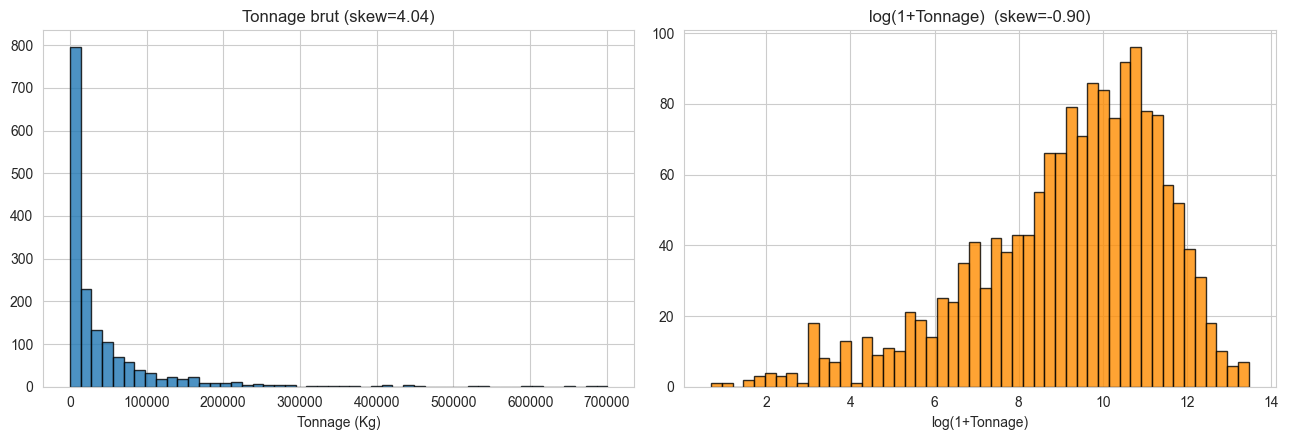

count      1629.000000
mean      43493.790781
std       77263.212890
min           1.000000
25%        2760.000000
50%       15020.000000
75%       50228.513300
max      700513.000000
Name: Tonnage (Kg), dtype: float64

In [2]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(train["Tonnage (Kg)"], bins=50, edgecolor="black", alpha=0.8)
axes[0].set_title(f"Tonnage brut (skew={train['Tonnage (Kg)'].skew():.2f})")
axes[0].set_xlabel("Tonnage (Kg)")

axes[1].hist(train["log_tonnage"], bins=50, edgecolor="black", alpha=0.8, color="darkorange")
axes[1].set_title(f"log(1+Tonnage)  (skew={train['log_tonnage'].skew():.2f})")
axes[1].set_xlabel("log(1+Tonnage)")
plt.tight_layout()
plt.show()

train["Tonnage (Kg)"].describe()


## 2. Calendrier de récolte

Le volume mensuel reflète l'étalement de récolte décrit dans le guide (clémentines précoces oct-déc, oranges de saison janv-avr, variétés tardives avr-juin).

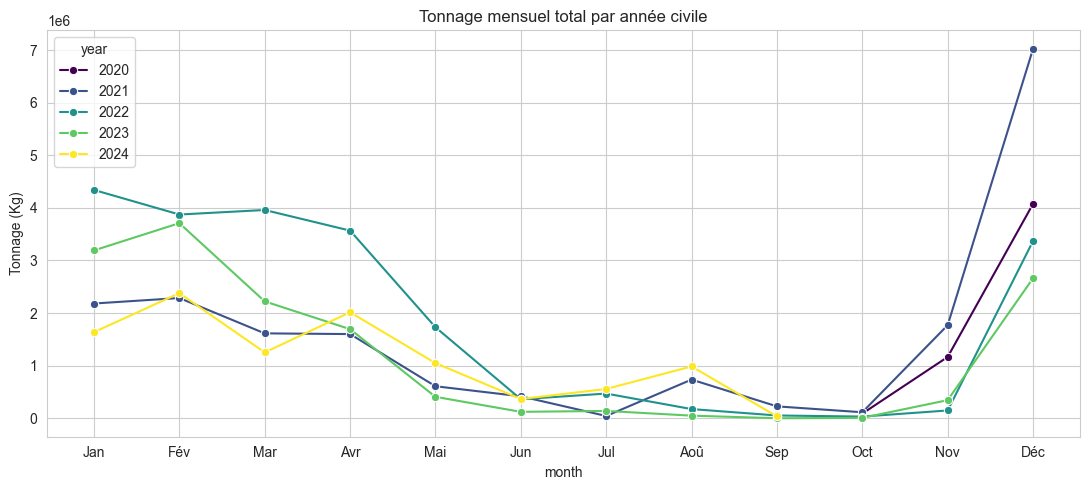

In [3]:

monthly = train.groupby(["year", "month"])["Tonnage (Kg)"].sum().reset_index()
plt.figure(figsize=(11, 5))
sns.lineplot(data=monthly, x="month", y="Tonnage (Kg)", hue="year", marker="o", palette="viridis")
plt.xticks(range(1, 13), ["Jan","Fév","Mar","Avr","Mai","Jun","Jul","Aoû","Sep","Oct","Nov","Déc"])
plt.title("Tonnage mensuel total par année civile")
plt.tight_layout()
plt.show()


## 3. Répartition Région × Campagne

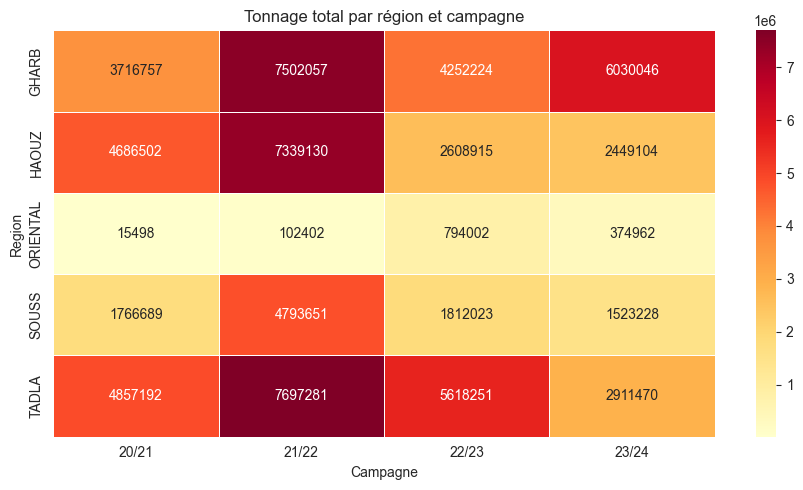

Campagne,20/21,21/22,22/23,23/24
Region,,,,
GHARB,3.716757e+06,7.502057e+06,4.252224e+06,6.030046e+06
HAOUZ,4.686502e+06,7.339130e+06,2.608915e+06,2.449104e+06
ORIENTAL,1.549804e+04,1.024019e+05,7.940023e+05,3.749623e+05
SOUSS,1.766689e+06,4.793651e+06,1.812023e+06,1.523228e+06
TADLA,4.857192e+06,7.697281e+06,5.618251e+06,2.911470e+06


In [4]:

pivot = pd.pivot_table(train, values="Tonnage (Kg)", index="Region", columns="Campagne",
                        aggfunc="sum", fill_value=0)
plt.figure(figsize=(9, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.5)
plt.title("Tonnage total par région et campagne")
plt.tight_layout()
plt.show()
pivot


## 4. Ordres de grandeur NPK / irrigation

Le guide cite 150-250 kg N/ha/an et quelques milliers de m³/ha/an ; les cumuls sur 12 mois doivent rester dans des plages comparables.

In [5]:

print("Cumul N sur 12 mois glissants (kg) - describe:")
print(train["N_cum_12m"].describe())
print("\nCumul irrigation sur 12 mois glissants (m3) - describe:")
print(train["Irrigation_m3_cum_12m"].describe())
assert train["N_cum_12m"].max() < 1e5, "Ordre de grandeur suspect"
print("\nOK - ordres de grandeur plausibles.")


Cumul N sur 12 mois glissants (kg) - describe:
count    1583.000000
mean      157.166014
std       346.137461
min         0.000000
25%         0.072177
50%        14.060726
75%       157.845838
max      3900.596968
Name: N_cum_12m, dtype: float64

Cumul irrigation sur 12 mois glissants (m3) - describe:
count      1583.000000
mean      15587.559605
std       19041.413717
min           0.000000
25%        3566.959837
50%        8628.486495
75%       20230.610924
max      154375.000000
Name: Irrigation_m3_cum_12m, dtype: float64

OK - ordres de grandeur plausibles.


## 5. Corrélations avec la cible (log tonnage)

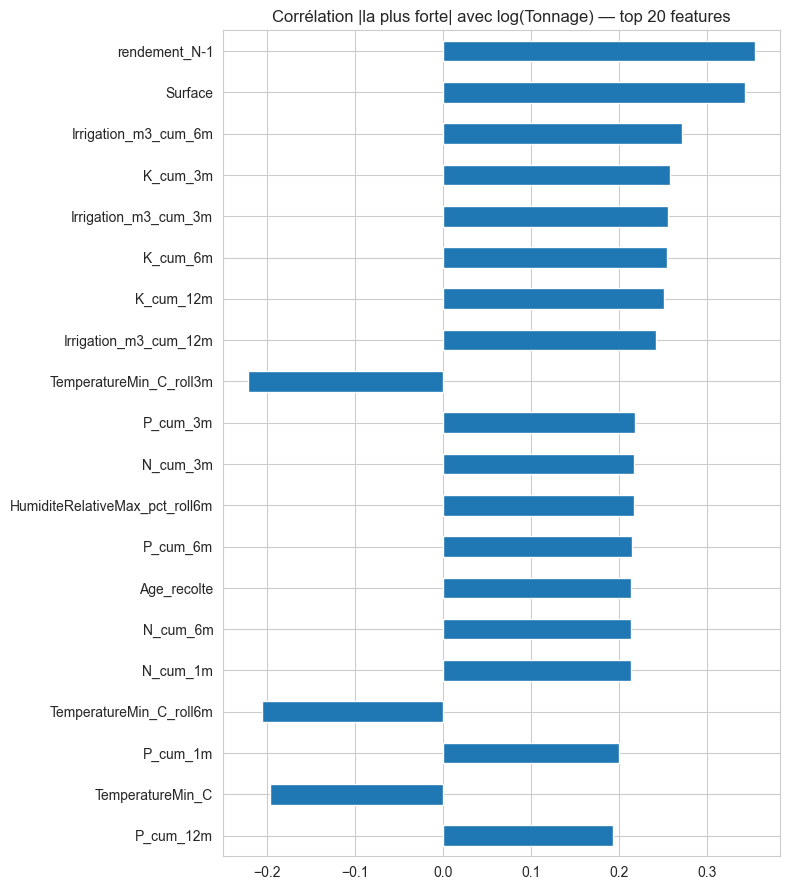

rendement_N-1                     0.353897
Surface                           0.342838
Irrigation_m3_cum_6m              0.271848
K_cum_3m                          0.257249
Irrigation_m3_cum_3m              0.255637
K_cum_6m                          0.254797
K_cum_12m                         0.250417
Irrigation_m3_cum_12m             0.241762
TemperatureMin_C_roll3m          -0.221629
P_cum_3m                          0.218408
N_cum_3m                          0.217202
HumiditeRelativeMax_pct_roll6m    0.217052
P_cum_6m                          0.213936
Age_recolte                       0.213662
N_cum_6m                          0.213476
N_cum_1m                          0.212993
TemperatureMin_C_roll6m          -0.205804
P_cum_1m                          0.200173
TemperatureMin_C                 -0.197524
P_cum_12m                         0.193260
Name: log_tonnage, dtype: float64

In [6]:

num_cols = [c for c in train.columns if train[c].dtype != "object"
            and c not in ["id", "log_tonnage", "Tonnage (Kg)", "month_idx", "year", "month"]]
corr = train[num_cols + ["log_tonnage"]].corr()["log_tonnage"].drop("log_tonnage").sort_values(key=abs, ascending=False)
plt.figure(figsize=(8, 9))
corr.head(20).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Corrélation |la plus forte| avec log(Tonnage) — top 20 features")
plt.tight_layout()
plt.show()
corr.head(20)


## 6. Âge du verger et rendement

Le guide décrit une relation non linéaire (phase juvénile, montée en charge, plateau, déclin).

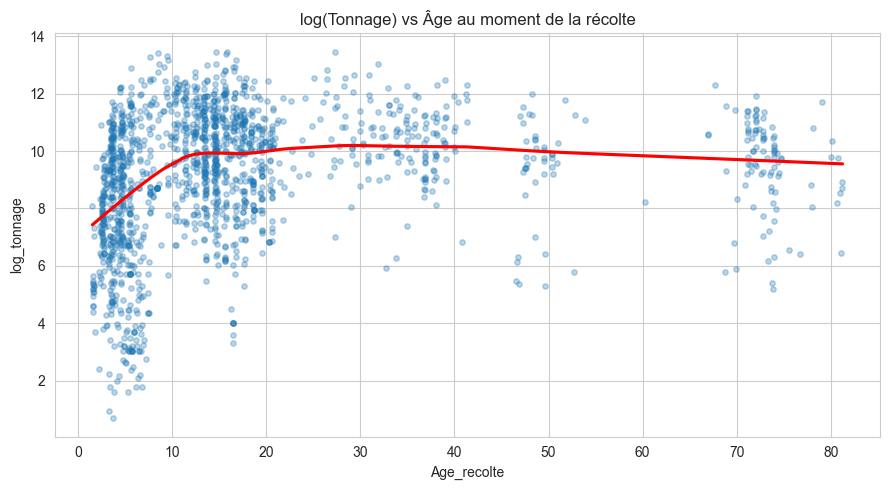

In [7]:

plt.figure(figsize=(9, 5))
sns.regplot(data=train, x="Age_recolte", y="log_tonnage", lowess=True,
            scatter_kws=dict(alpha=0.3, s=15), line_kws=dict(color="red"))
plt.title("log(Tonnage) vs Âge au moment de la récolte")
plt.tight_layout()
plt.show()


## 7. Alternance : rendement N-1 vs rendement courant

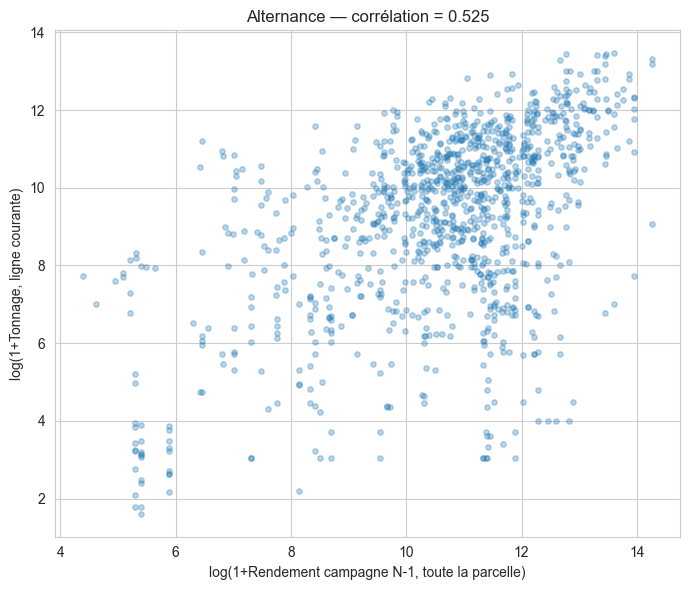

In [8]:

sub = train.dropna(subset=["rendement_N-1"])
plt.figure(figsize=(7, 6))
plt.scatter(np.log1p(sub["rendement_N-1"]), sub["log_tonnage"], alpha=0.3, s=15)
plt.xlabel("log(1+Rendement campagne N-1, toute la parcelle)")
plt.ylabel("log(1+Tonnage, ligne courante)")
plt.title(f"Alternance — corrélation = {np.corrcoef(np.log1p(sub['rendement_N-1']), sub['log_tonnage'])[0,1]:.3f}")
plt.tight_layout()
plt.show()


## 8. Source du climat utilisée (site propre vs repli régional)

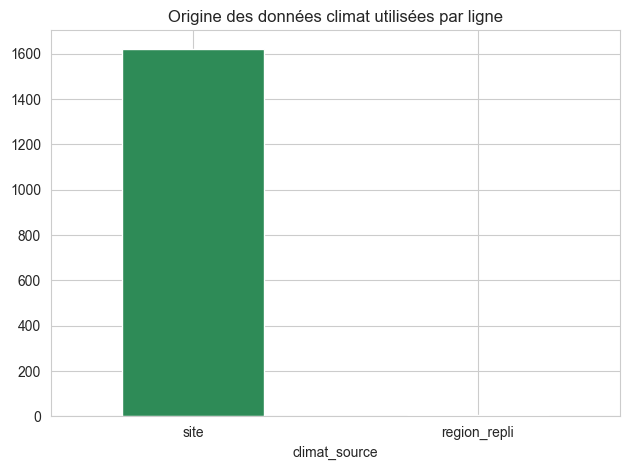

In [9]:

train["climat_source"].value_counts().plot(kind="bar", color=["seagreen", "salmon"])
plt.title("Origine des données climat utilisées par ligne")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
